In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

In [2]:
df = pd.read_csv('../Datasets/Fashion_Trends.csv')

In [35]:
df

,Brand,Description,Product_ID,Discount_Price,Original_Price,Gender,Category,Discounted_amount,Discount_Percentage,Product_Name,Price_Segment,Discount_Tier
0,performax,Typographic Print Track Pants with Insert Pockets,441136763008,974,1299,Men,Activewear,325,25.02,Track Pants,Mid (₹500–₹1499),Moderate (20-40%)
1,performax,Low-Top Lace-Up Sports Shoes,450137679013,1499,1499,Men,Activewear,0,0.00,Sports Shoes,Mid (₹500–₹1499),No Discount
2,teamspirit,Colorblock Crew-Neck T-shirt,441133214008,461,549,Men,Activewear,88,16.03,Crew-Neck T-shirt,Mid (₹500–₹1499),Light (10-20%)
3,performax,Camouflage Print Joggers with Insert Pockets,441134776020,1189,1699,Men,Activewear,510,30.02,Print Joggers,Premium (₹1500–₹3999),Moderate (20-40%)
4,teamspirit,Reflective Colourblock Crew-Neck T-shirt,441136539020,425,599,Men,Activewear,174,29.05,Crew-Neck T-shirt,Mid (₹500–₹1499),Moderate (20-40%)
...,...,...,...,...,...,...,...,...,...,...,...,...
31577,ajio,Printed Top with Raglan Sleeves,460328028004,1299,1299,Women,Westernwear,0,0.00,Printed Top,Mid (₹500–₹1499),No Discount
31578,ajio,Striped Cropped Pants with Belt,460328036004,2099,2099,Women,Westernwear,0,0.00,Cropped Pants,Premium (₹1500–₹3999),No Discount
31579,ajio,Striped City Shorts with Belt,460328005002,1499,1499,Women,Westernwear,0,0.00,City Shorts,Mid (₹500–₹1499),No Discount
31580,ajio,Denim Jacket with Frayed Hemline,460328651009,2999,2999,Women,Westernwear,0,0.00,Denim Jacket,Premium (₹1500–₹3999),No Discount


In [3]:
sage_palette = ['#A3B18A', '#8FAF8F', '#6B8E6B', '#344E41']

sb.set_theme(style="white", palette=sage_palette)

# Data Preparation:

## Check and handle missing values

In [97]:
df.isnull().sum()

Brand                  0
Description            0
Product_ID             0
Discount_Price         0
Original_Price         0
Gender                 0
Category               0
Discounted_amount      0
Discount_Percentage    0
Product_Name           0
Price_Segment          0
Discount_Tier          0
dtype: int64

## Ensure datatypes are in correct format

In [6]:
df.dtypes

Brand                   object
Description             object
Product_ID               int64
Discount_Price           int64
Original_Price           int64
Gender                  object
Category                object
Discounted_amount        int64
Discount_Percentage    float64
Product_Name            object
Price_Segment           object
Discount_Tier           object
dtype: object

# Exploratory Data Analysis (EDA):

## Distribution of numerical features

In [7]:
df.describe()

,Product_ID,Discount_Price,Original_Price,Discounted_amount,Discount_Percentage
count,3.158200e+04,31582.000000,31582.000000,31582.000000,31582.000000
mean,4.439001e+11,929.759832,1418.094769,488.334938,32.979031
std,5.715579e+09,727.207471,945.684511,544.062245,24.667178
min,4.200088e+11,75.000000,149.000000,0.000000,0.000000
25%,4.411142e+11,479.000000,799.000000,0.000000,0.000000
50%,4.411360e+11,735.000000,1299.000000,356.000000,35.040000
75%,4.501273e+11,1199.000000,1799.000000,749.000000,50.930000
max,4.608526e+11,16999.000000,19999.000000,11999.000000,85.010000


## Frequent distribution of categorical features

In [8]:
df.Brand.value_counts()

Brand
performax                3029
teamspirit               1908
dnmx                     1757
netplay                  1698
avaasa-mix-n-match       1507
                         ... 
bon-bon                     1
awb                         1
hk-colours-of-fashion       1
jadu                        1
classic-polo                1
Name: count, Length: 191, dtype: int64

In [9]:
df.Description.value_counts()

Description
Checked Slim Fit Shirt with Patch Pocket       571
Typographic Print Crew-Neck T-shirt            506
Slim Fit Shirt with Patch Pocket               326
Checked Shirt with Patch Pocket                262
Printed Straight Kurta                         261
                                              ... 
Straight Kurta & Printed Pant Set                1
Geometric Print Straight Kurta with Pompoms      1
Handblock Print Dupatta                          1
Floral Fit & Flare Kurta with Side Tie-Ups       1
Checked Wrap-Around Mini Skirt                   1
Name: count, Length: 11771, dtype: int64

In [10]:
df.Category.value_counts()

Category
Topwear        7110
Westernwear    6641
Footwear       6030
Ethnicwear     5265
Bottomwear     2984
Activewear     2134
Fusionwear      997
Lingerie        325
Innerwear        96
Name: count, dtype: int64

In [11]:
df.Product_Name.value_counts()

Product_Name
Crew-Neck T-shirt        2312
Straight Kurta           2126
Fit Shirt                2117
Polo T-shirt             1126
A-line Kurta              803
                         ... 
Self-Designed Shirt         1
fit Shirt                   1
Heavy-Wash Shirt            1
Waistcoat                   1
Polka-Dotted Trousers       1
Name: count, Length: 1799, dtype: int64

In [12]:
df.Gender.value_counts()

Gender
Women    17207
Men      14375
Name: count, dtype: int64

## Identify outliers in Price and Discount

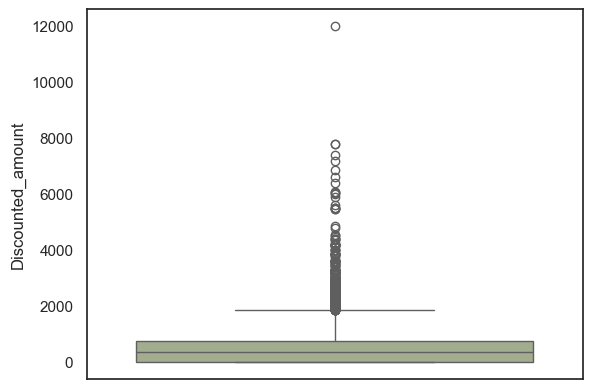

In [4]:
sb.boxplot(df.Discounted_amount)
plt.show()

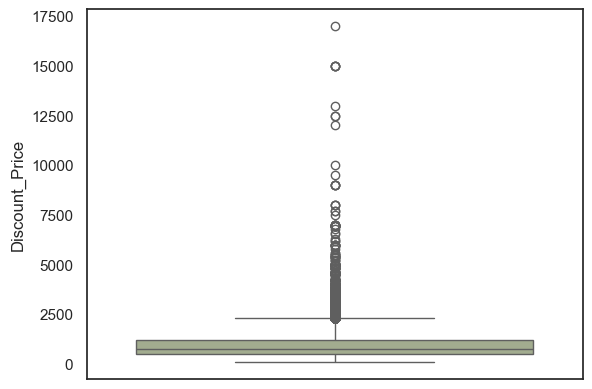

In [5]:
sb.boxplot(df.Discount_Price)
plt.show()

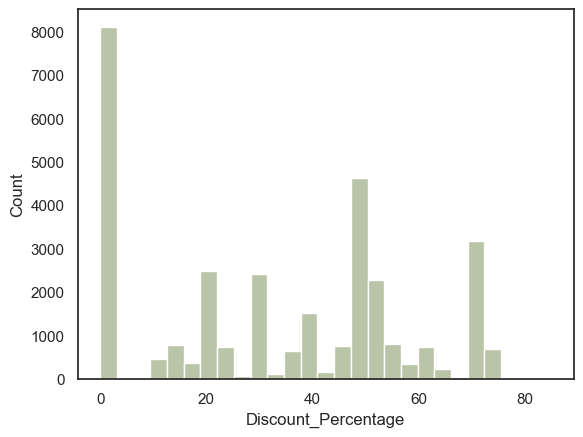

In [6]:
sb.histplot(df.Discount_Percentage)
plt.show()

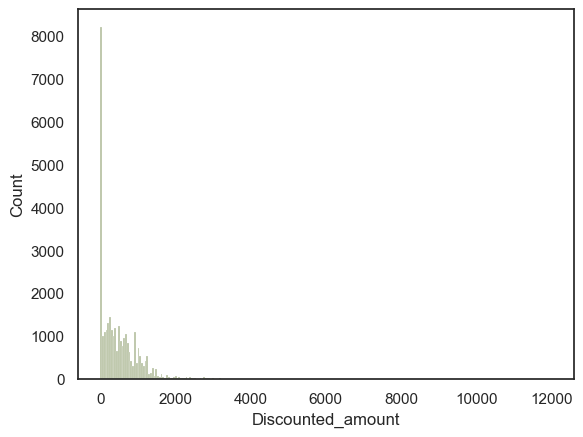

In [7]:
sb.histplot(df.Discounted_amount)
plt.show()

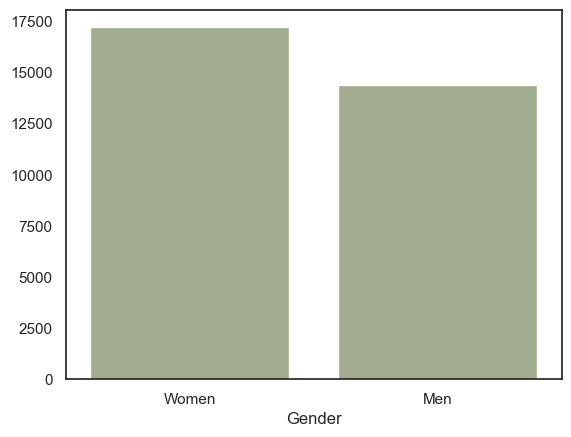

In [8]:
a = df.Gender.value_counts()
sb.barplot(x=a.index,y=a.values)
plt.show()

# Brand and Category Analysis:

## Top Brands:

### Which brands have the most products

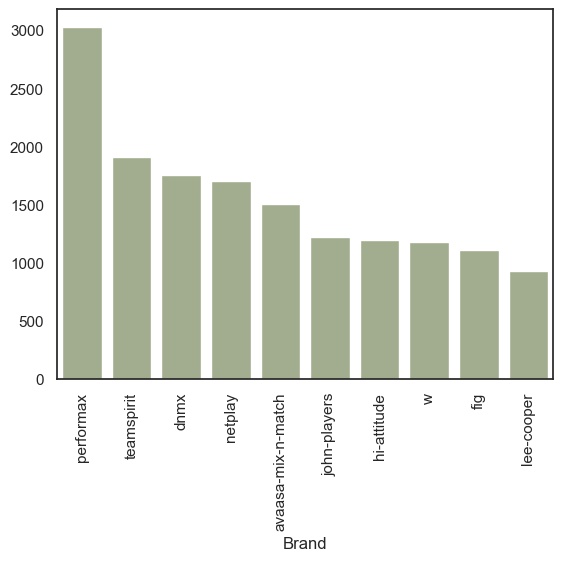

In [9]:
b = df['Brand'].value_counts().nlargest(10)
sb.barplot(x=b.index,y=b.values)
plt.xticks(rotation=90)
plt.show()

#### The chart shows that product availability is concentrated among a few brands. Performax leads with 3,029 products, followed by Teamspirit with 1,908, DNMX with 1,757, Netplay with 1,698, and Avaasa Mix-N-Match with 1,507. This indicates that these brands have a comparatively strong presence in the dataset. However, a higher product count indicates greater assortment or catalog representation, not necessarily higher sales, revenue, or customer preference.

# Category Analysis:

### Which categories dominate overall?

In [5]:
a = df['Category'].value_counts()
a

Category
Topwear        7110
Westernwear    6641
Footwear       6030
Ethnicwear     5265
Bottomwear     2984
Activewear     2134
Fusionwear      997
Lingerie        325
Innerwear        96
Name: count, dtype: int64

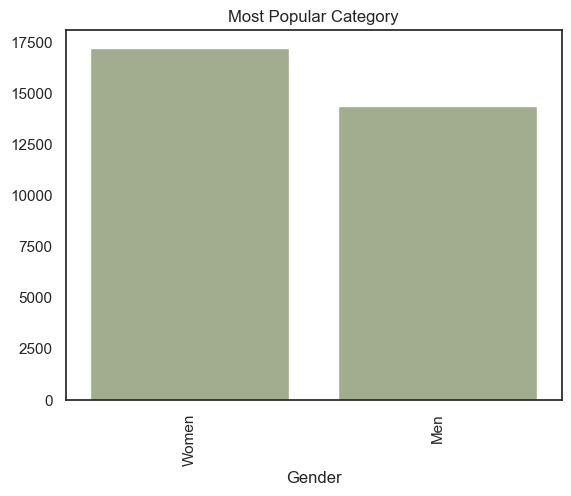

In [10]:
sb.barplot(x=a.index,y=a.values)
plt.xticks(rotation=90)
plt.title("Most Popular Category")
plt.show()

#### Topwear is the largest category, with 7,110 products, followed by Westernwear with 6,641, Footwear with 6,030, and Ethnicwear with 5,265. Together, these four categories account for approximately 79.3% of all listed products. Innerwear and Lingerie have the lowest representation, with 96 and 325 products, respectively. This suggests that the dataset's product assortment is primarily concentrated in topwear, westernwear, footwear, and ethnicwear.

# Category vs Price Segment:

### Which categories dominate in Budget, Mid, Premium, Luxury?

In [12]:
p = df.groupby(['Price_Segment','Category']).size().reset_index(name='count')
p

,Price_Segment,Category,count
0,Low (<₹500),Activewear,156
1,Low (<₹500),Bottomwear,79
2,Low (<₹500),Ethnicwear,588
3,Low (<₹500),Footwear,725
4,Low (<₹500),Fusionwear,25
5,Low (<₹500),Innerwear,83
6,Low (<₹500),Lingerie,153
7,Low (<₹500),Topwear,515
8,Low (<₹500),Westernwear,648
9,Luxury (₹4000+),Activewear,9


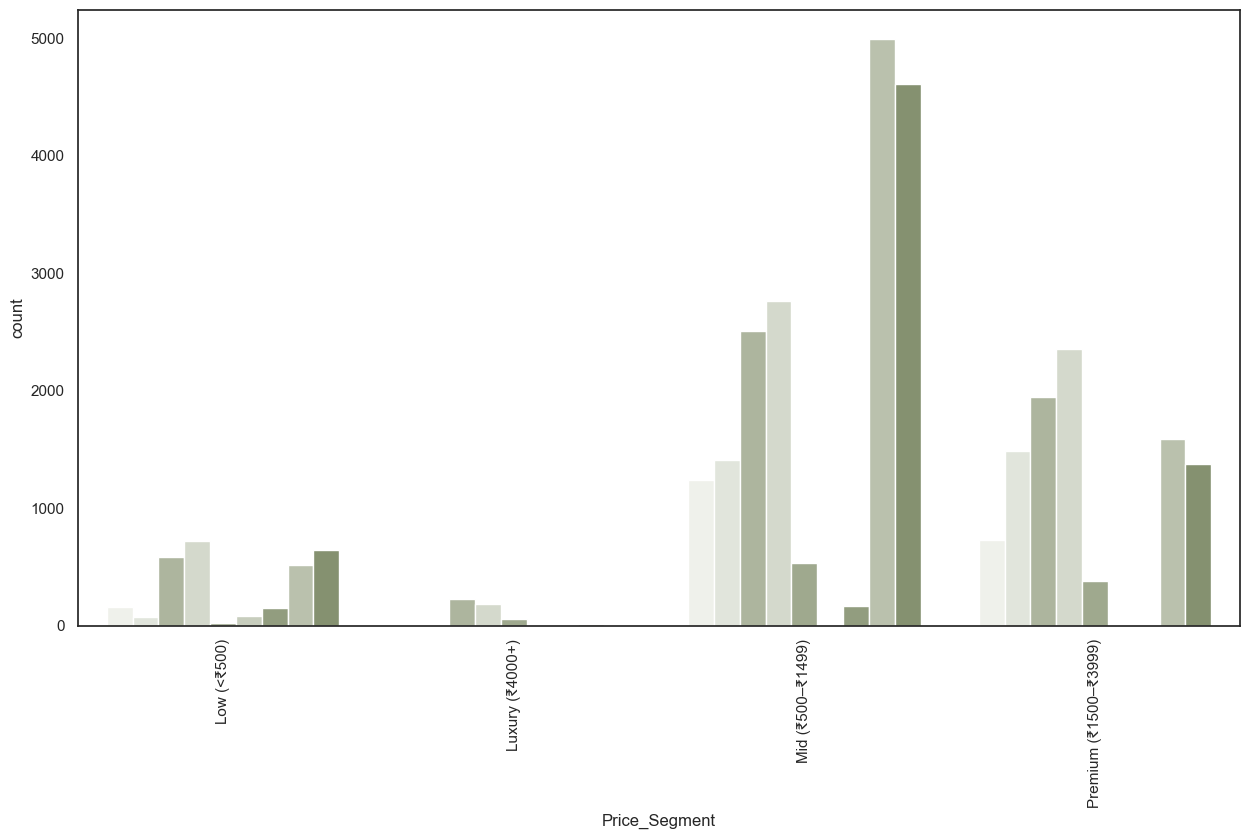

In [28]:
plt.figure(figsize=(15,8))
sb.barplot(data=p,x='Price_Segment',y='count',hue='Category',palette=dict(zip(df["Category"].unique(), sage_palette)),legend=False)
plt.xticks(rotation=90)
plt.show()


#### The chart compares the number of products from each category across Budget, Mid, Premium, and Luxury price segments. It helps identify which categories have a broader assortment in each price range and which categories are more concentrated in specific segments. Categories with higher product counts represent a larger share of the available assortment within those segments. These findings can support product assortment planning and pricing strategies, although product count alone does not establish customer demand or profitability.

# Product Type Analysis:

### Which product types are most common?

In [23]:
df.Product_Name.value_counts()

Product_Name
Crew-Neck T-shirt        2312
Straight Kurta           2126
Fit Shirt                2117
Polo T-shirt             1126
A-line Kurta              803
                         ... 
Self-Designed Shirt         1
fit Shirt                   1
Heavy-Wash Shirt            1
Waistcoat                   1
Polka-Dotted Trousers       1
Name: count, Length: 1799, dtype: int64

## Compare product type distribution across genders

In [31]:
c = df.groupby(['Gender','Product_Name']).size().reset_index(name = 'count').sort_values('count',ascending=False)
c = c.groupby('Gender').head(10)
c

,Gender,Product_Name,count
1736,Women,Straight Kurta,2113
161,Men,Fit Shirt,2087
100,Men,Crew-Neck T-shirt,1620
328,Men,Polo T-shirt,1105
614,Women,A-line Kurta,803
849,Women,Crew-Neck T-shirt,692
156,Men,Fit Jeans,622
613,Women,A-line Dress,447
925,Women,Dress Material,419
1014,Women,Flared Kurta,405


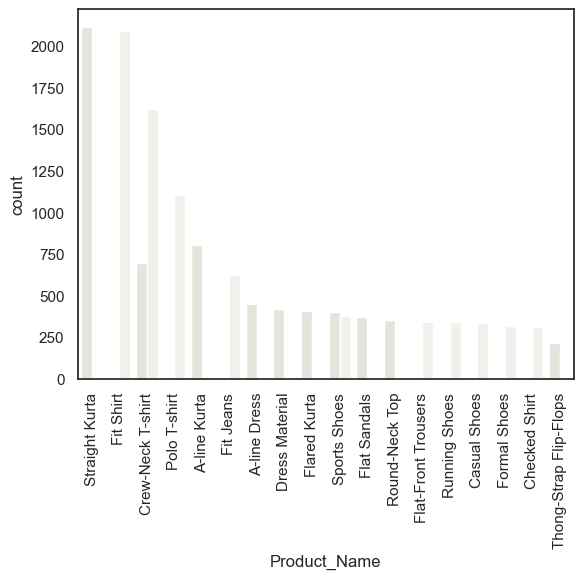

In [33]:
sb.barplot(data=c,x='Product_Name',y='count',hue='Gender',palette="ch:start=.2,rot=-.3")
plt.xticks(rotation=90)
plt.show()


#### The chart shows that Straight Kurta is the most common product among women, while Fit Shirt is the most common among men. Product preferences vary by gender, highlighting the importance of gender-specific product assortment and marketing strategies.

## Identify top product types within each category

In [34]:
e = df.groupby(['Category','Product_Name']).size().reset_index(name = 'count').sort_values('count',ascending=False)
e = e.groupby('Category').head(5)
e

,Category,Product_Name,count
662,Ethnicwear,Straight Kurta,2076
1422,Topwear,Fit Shirt,2070
1396,Topwear,Crew-Neck T-shirt,1411
1491,Topwear,Polo T-shirt,1061
428,Ethnicwear,A-line Kurta,764
1758,Westernwear,Crew-Neck T-shirt,665
275,Bottomwear,Fit Jeans,580
800,Footwear,Flat Sandals,535
1043,Footwear,Thong-Strap Flip-Flops,452
745,Footwear,Casual Shoes,446


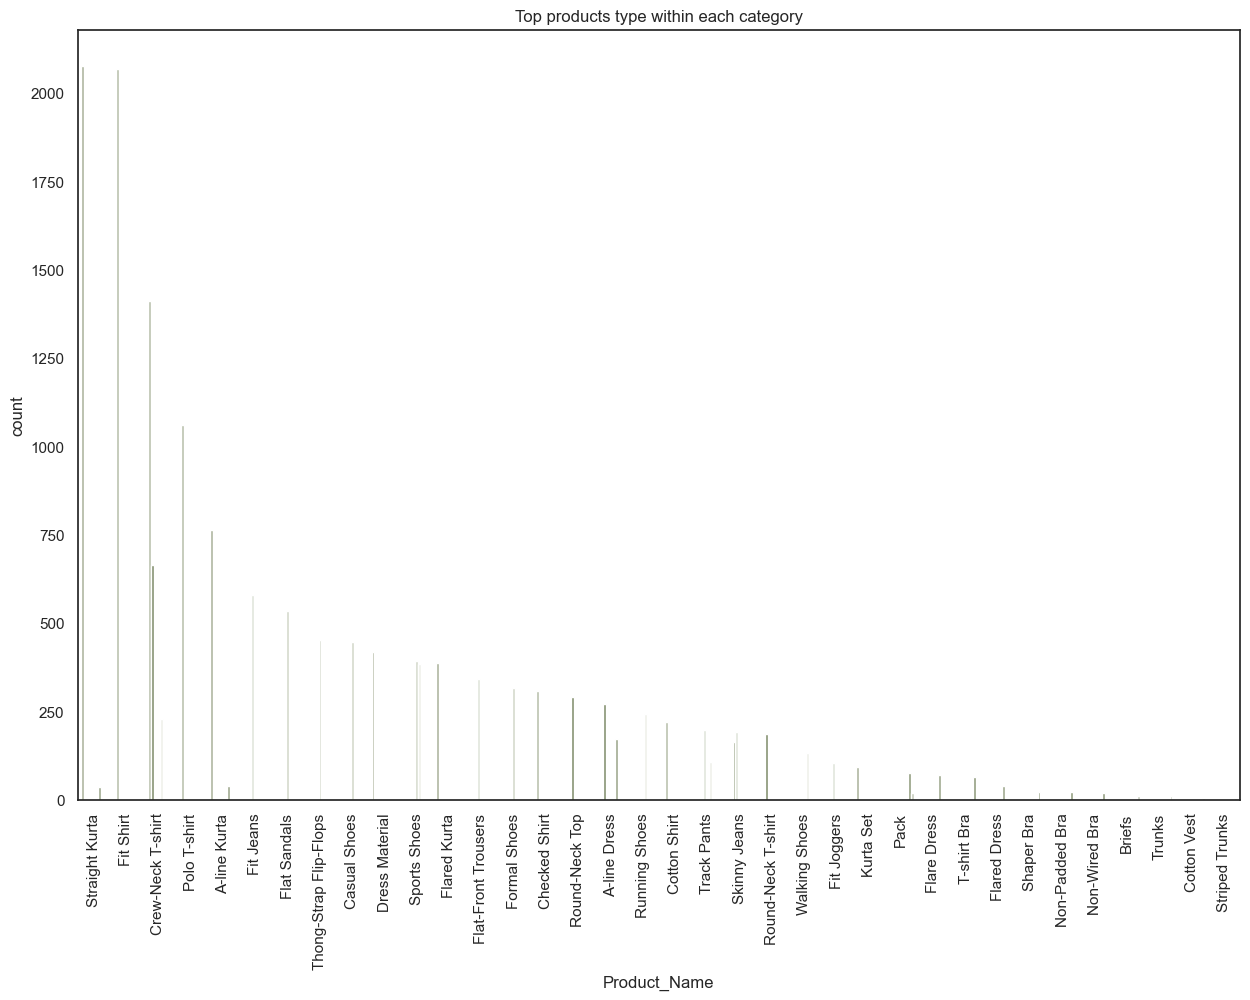

In [36]:
plt.figure(figsize=(15,10))
sb.barplot(data=e,x='Product_Name',y='count',hue='Category',palette=dict(zip(df["Category"].unique(), sage_palette)),legend=False)
plt.title("Top products type within each category")
plt.xticks(rotation=90)
plt.show()


#### The chart identifies the most common product types within each fashion category. It helps explain which individual products contribute most to the assortment of categories such as Topwear, Bottomwear, Footwear, and Ethnicwear. For example, the high representation of T-shirts and kurtas in the overall dataset highlights the importance of these product types in the catalog. This analysis can help businesses organize product collections and identify opportunities to expand or balance their assortments.

# Discount Analysis:

## Discount Tier Comparison:

### How many products fall into each discount tier?

In [67]:
df.groupby('Discount_Tier').size()

Discount_Tier
 No Discount           8107
Deep (>40%)           15194
Light (10-20%)         1621
Moderate  (20-40%)     6660
dtype: int64

## Discount % vs Product Type:

### Which product types get the highest average discount?

In [25]:
pp= df.groupby('Product_Name')['Discount_Percentage'].mean().nlargest(10)
pp

Product_Name
Brocade Angarakha    80.00
Brocade Tunic        80.00
Chanderi Kurta       79.99
Chanderi Top         79.99
Black Cardigan       74.99
Black Gillet         74.99
Blue Jeans           74.99
Blue Shacket         74.99
Button-Down Shrug    74.99
Chanderi Tunic       74.99
Name: Discount_Percentage, dtype: float64

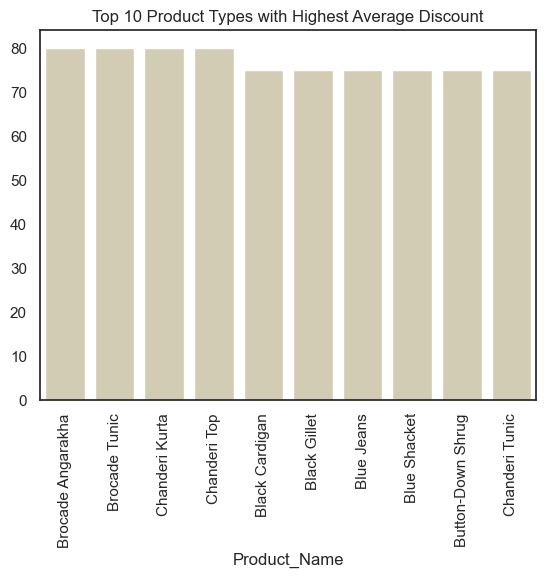

In [37]:
sb.barplot(x=pp.index,y=pp.values,color="#D8CFB0")
plt.title("Top 10 Product Types with Highest Average Discount")
plt.xticks(rotation=90)
plt.show()

#### The chart compares the average discount percentages of product types with the highest mean discounts. It highlights which product types receive relatively larger price reductions and may help identify areas where promotional pricing is more prominent. Retailers can use these insights to review discount policies, compare promotional strategies, and investigate whether larger discounts are associated with particular product types. However, high average discounts do not necessarily imply high sales or successful promotions.

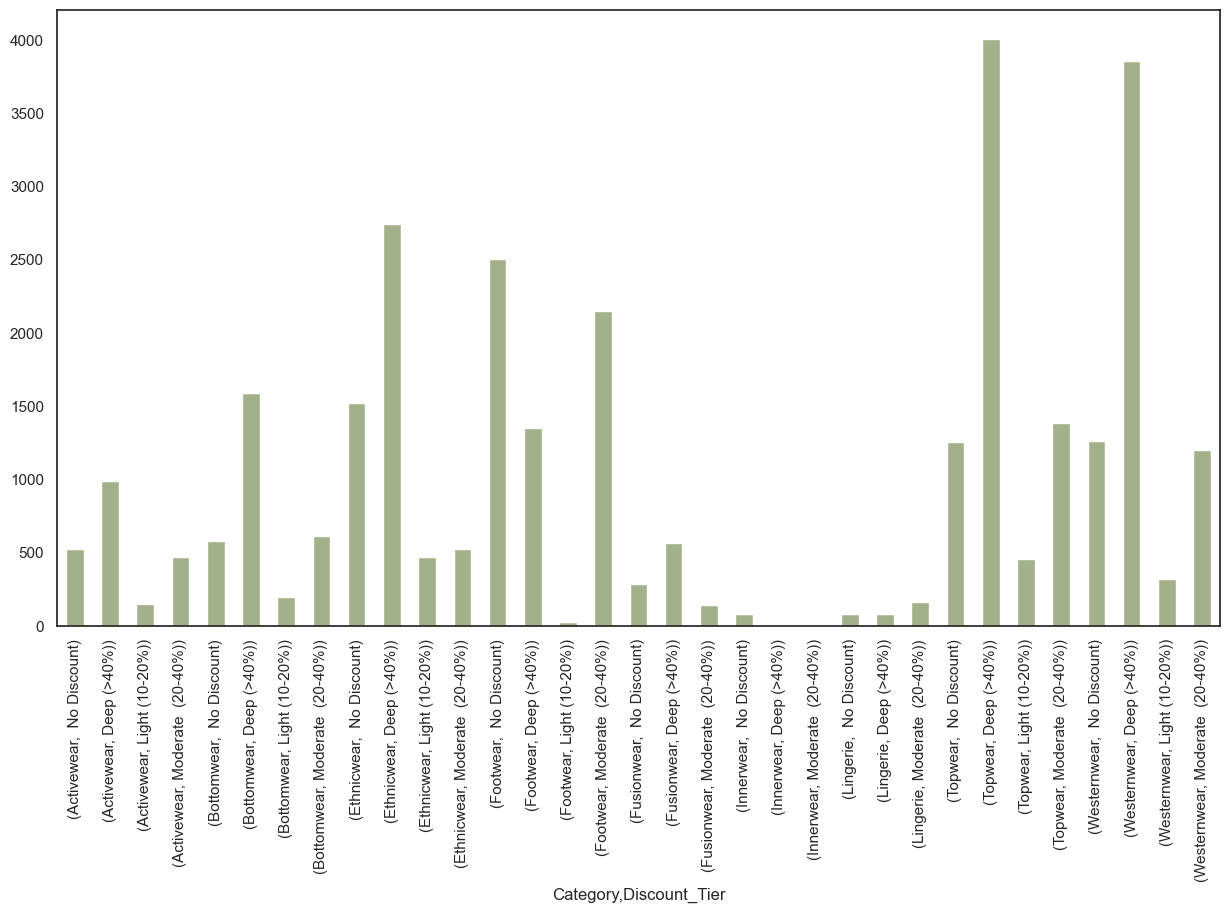

In [23]:
d = df.groupby(['Category','Discount_Tier']).size()
plt.figure(figsize=(15,8))
d.plot(kind='bar',stacked=True)
plt.show()

#### The chart shows that discount distribution varies across fashion categories. Topwear and Westernwear have higher product counts across multiple discount tiers, while some categories contain more products with no discount. This analysis helps compare discount patterns and improve category-wise pricing strategies.

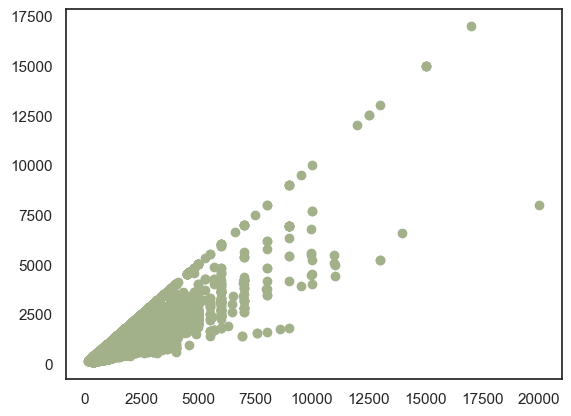

In [14]:
plt.scatter(df.Original_Price,df.Discount_Price)

#### The scatter plot shows a positive relationship between original price and discount price, meaning higher-priced products generally have higher discounted prices. However, some products deviate from this pattern, indicating variations in pricing and discount strategies.

# Gender-Based Preferences:

### Which categories and product types dominate for Men vs Women vs Kids?

In [19]:
v = df.groupby(['Gender','Category']).size().reset_index(name = 'count').sort_values(['Gender','count'],ascending=[True,False]).head(10)
b = df.groupby(['Gender','Product_Name']).size().reset_index(name = 'count').sort_values(['Gender','count'],ascending=[True,False]).head(10)


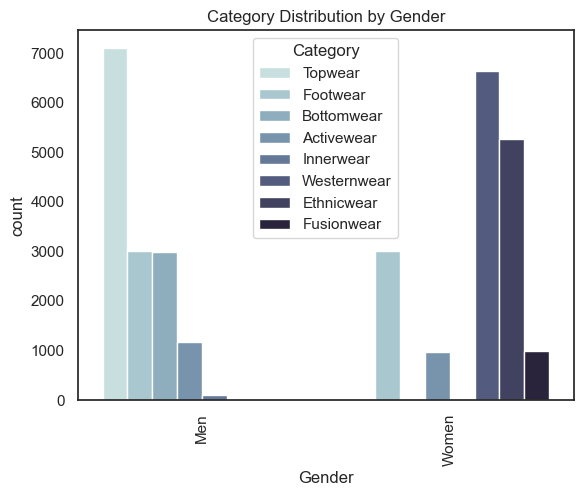

In [21]:
sb.barplot(data=v,x='Gender',y='count',hue='Category',palette="ch:start=.2,rot=-.3")
plt.title("Category Distribution by Gender")
plt.xticks(rotation=90)
plt.show()


#### The chart compares the representation of fashion categories across gender groups. It helps identify the categories with the largest product assortments for Men, Women, and Kids, revealing differences in catalog composition. These insights can assist retailers in tailoring product collections and organizing gender-specific offerings. However, the chart measures product availability rather than customer preferences, which would require sales or customer behavior data to establish.

## Gender-wise average discount%

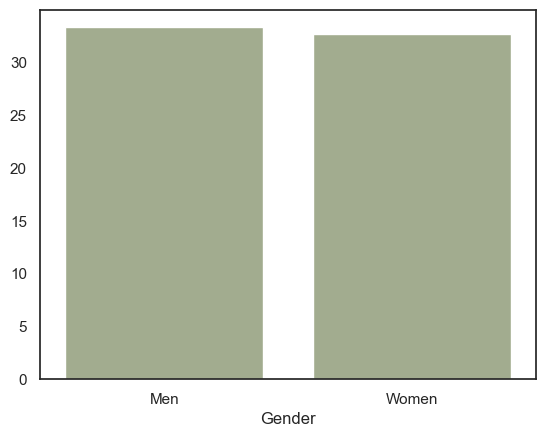

In [15]:
t = df.groupby('Gender')['Discount_Percentage'].mean()
sb.barplot(x=t.index,y=t.values)
plt.show()

#### The analysis shows that men's products receive an average discount of approximately 33.32%, while women's products receive an average discount of approximately 32.69%. Men's products therefore have a slightly higher average discount, by about 0.62 percentage points. The difference is relatively small, suggesting that the average discount levels for the two groups are broadly similar. Further analysis would be needed to determine whether this difference is statistically meaningful or commercially significant.

# Price Segment Analysis:

## Distribution of products across Budget, Mid, Premium, Luxury

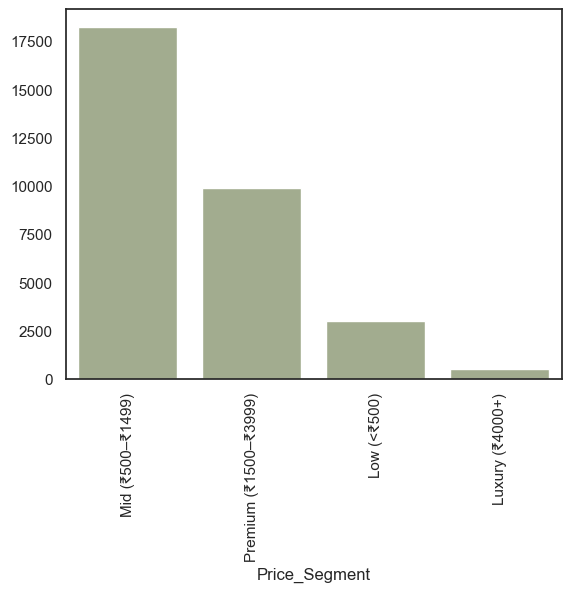

In [16]:
h = df['Price_Segment'].value_counts()
sb.barplot(x=h.index,y=h.values)
plt.xticks(rotation=90)
plt.show()

#### The chart compares category representation across the four price segments. It helps identify the categories that contribute most to the Budget, Mid, Premium, and Luxury assortments and reveals how product availability varies by price level. This information can support category-level pricing decisions, assortment allocation, and market positioning. However, a large number of products in a segment does not necessarily mean that the segment generates the highest revenue.

### Which categories dominate in each segment?

In [14]:
pd.crosstab(df['Category'],df['Price_Segment'])

Price_Segment,Low (<₹500),Luxury (₹4000+),Mid (₹500–₹1499),Premium (₹1500–₹3999)
Category,,,,
Activewear,156,9,1237,732
Bottomwear,79,3,1414,1488
Ethnicwear,588,227,2506,1944
Footwear,725,182,2766,2357
Fusionwear,25,61,532,379
Innerwear,83,0,11,2
Lingerie,153,0,171,1
Topwear,515,15,4989,1591
Westernwear,648,4,4611,1378


#### Topwear has the highest number of products in the Mid-price segment, followed by Westernwear. Footwear and Ethnicwear have strong representation in the Premium segment, while Luxury products are relatively limited across most categories. This indicates that the catalog mainly focuses on mid-range and premium-priced fashion products.

## Compare Brand positioning(budget vs premium brands)

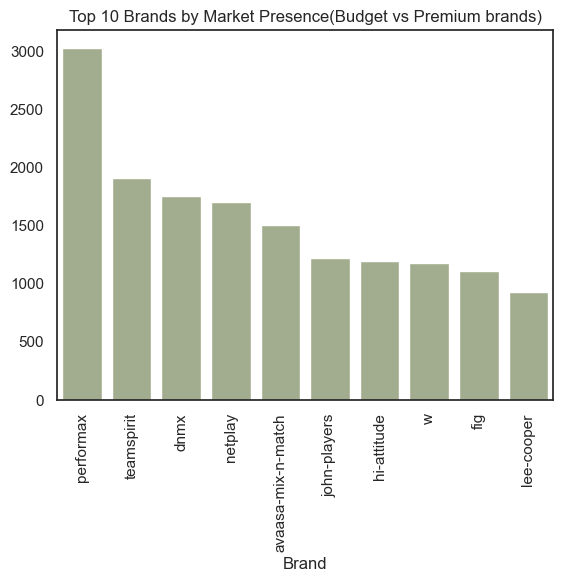

In [17]:
o = df.groupby(['Brand','Price_Segment']).size().reset_index(name='count').sort_values('count',ascending=False)
o = o.groupby('Brand')['count'].sum().nlargest(10)
sb.barplot(x=o.index,y=o.values)
plt.title("Top 10 Brands by Market Presence(Budget vs Premium brands)")
plt.xticks(rotation=90)
plt.show()

#### The chart identifies the ten brands with the highest product counts in the dataset. Performax leads with 3,029 products, followed by Teamspirit, DNMX, Netplay, and Avaasa Mix-N-Match. This indicates that these brands have a stronger catalog presence than other brands in the dataset. To compare budget versus premium positioning accurately, the number of products for each brand should also be broken down by price segment. Overall product count alone cannot establish whether a brand is budget-oriented or premium-oriented.